# Hito 2 — EfficientNet-B0 vs. YOLO26n-cls

## 1. Librerías y preparación de datos

In [4]:
import os, json, random, shutil, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from PIL import Image
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)
from sklearn.metrics import auc, precision_recall_curve
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
DISP='cuda' if torch.cuda.is_available() else 'cpu'
DATOS=Path('datos'); SALIDA=Path('resultados_modelos_imagenes'); SALIDA.mkdir(exist_ok=True)
print('Dispositivo:',DISP,'| PyTorch:',torch.__version__)

Dispositivo: cpu | PyTorch: 2.14.1+cpu


In [5]:
# Se copian las IMÁGENES ORIGINALES desde el ZIP de Kaggle a splits congelados.
# El script verifica SHA256 y conserva juntos los grupos de fotografías similares.
from preparar_casting import preparar
ZIP_KAGGLE = Path('archive (1).zip')
if not (DATOS/'train').exists() or not (DATOS/'manifiesto_splits.csv').exists():
    preparar(ZIP_KAGGLE, 'data/manifest.jsonl', DATOS)
assert sum(1 for _ in (DATOS/'train').rglob('*.jpeg'))==928
assert sum(1 for _ in (DATOS/'val').rglob('*.jpeg'))==186
assert sum(1 for _ in (DATOS/'test').rglob('*.jpeg'))==186
CLASES=['correcta','defectuosa']
for parte in ['train','val','test']:
    print(parte, {c:len(list((DATOS/parte/c).glob('*.jpeg'))) for c in CLASES})

train {'correcta': 371, 'defectuosa': 557}
val {'correcta': 74, 'defectuosa': 112}
test {'correcta': 74, 'defectuosa': 112}


In [6]:
from torchvision.datasets import ImageFolder
# Orden de clases leído desde la estructura de carpetas
train_base=ImageFolder(str(DATOS/'train')); val_base=ImageFolder(str(DATOS/'val')); test_base=ImageFolder(str(DATOS/'test'))
assert train_base.classes==val_base.classes==test_base.classes==CLASES
print('Etiquetas:',train_base.class_to_idx)

def rutas_y_labels(part):
    ds=ImageFolder(str(DATOS/part))
    return [(Path(r),CLASES[y]) for r,y in ds.samples]
VAL=rutas_y_labels('val'); TEST=rutas_y_labels('test')
RESULTADOS_VAL={}; RESULTADOS_TEST={}; PREDICCIONES={}

def metricas(y_real,y_pred,score_def=None):
    yreal=np.asarray([int(c=='defectuosa') for c in y_real]); ypred=np.asarray([int(c=='defectuosa') for c in y_pred])
    cm=confusion_matrix(yreal,ypred,labels=[0,1]); tn,fp,fn,tp=cm.ravel()
    out={'n':len(yreal),'accuracy':float(accuracy_score(yreal,ypred)),
         'accuracy_balanceada':float(balanced_accuracy_score(yreal,ypred)),
         'precision_defectuosa':float(precision_score(yreal,ypred,zero_division=0)),
         'recall_defectuosa':float(recall_score(yreal,ypred,zero_division=0)),
         'f1_defectuosa':float(f1_score(yreal,ypred,zero_division=0)),
         'fp':int(fp),'fn':int(fn),'tn':int(tn),'tp':int(tp), 'matriz_confusion':cm.tolist()}
    if score_def is not None and len(np.unique(yreal))==2:
        out['auroc']=float(roc_auc_score(yreal, np.asarray(score_def)))
    return out

def guardar_metricas(nombre, conjunto, reales,preds,scores=None):
    m=metricas(reales,preds,scores)
    (RESULTADOS_VAL if conjunto=='val' else RESULTADOS_TEST)[nombre]=m
    PREDICCIONES[(nombre,conjunto)]=pd.DataFrame({
        'ruta':[str(r) for r,_ in (VAL if conjunto=='val' else TEST)],
        'real':reales,'predicha':preds,
        'score_defecto':scores if scores is not None else [None]*len(reales)})
    print(f'{nombre} / {conjunto}: accuracy balanceada = {m["accuracy_balanceada"]:.2%}, F1 defectuosa = {m["f1_defectuosa"]:.2%}')
    return m

Etiquetas: {'correcta': 0, 'defectuosa': 1}


## 2. EfficientNet-B0

In [8]:
import timm
from torch.utils.data import DataLoader

modelo=timm.create_model('efficientnet_b0',pretrained=True,num_classes=2).to(DISP)
# Se conserva el preprocesamiento de timm aplicado en el cuaderno original.
config_pre=timm.data.resolve_model_data_config(modelo)
prep=timm.data.create_transform(**config_pre)
train_ds=ImageFolder(str(DATOS/'train'),transform=prep)
val_ds=ImageFolder(str(DATOS/'val'),transform=prep)
assert train_ds.classes==CLASES
train_loader=DataLoader(train_ds,batch_size=32,shuffle=True,num_workers=0)
val_loader=DataLoader(val_ds,batch_size=32,shuffle=False,num_workers=0)

def predecir_eff_loader(mod, loader):
    mod.eval(); preds=[]; probs=[]; reales=[]
    with torch.inference_mode():
        for xs,ys in loader:
            logits=mod(xs.to(DISP))
            pp=torch.softmax(logits,dim=1).cpu().numpy()
            probs.extend(pp[:,1].tolist());preds.extend(pp.argmax(1).tolist());reales.extend(ys.tolist())
    return [CLASES[i] for i in reales],[CLASES[i] for i in preds],probs

opt=torch.optim.AdamW(modelo.parameters(),lr=1e-4)
criterio=torch.nn.CrossEntropyLoss()
MEJOR_EFF=-1;hist_eff=[]; checkpoint_eff=SALIDA/'efficientnet_b0_best.pth'
for epoca in range(1,3):
    modelo.train(); losses=[]
    for x,y in train_loader:
        opt.zero_grad(set_to_none=True)
        loss=criterio(modelo(x.to(DISP)),y.to(DISP))
        loss.backward(); opt.step()
        losses.append(loss.item())
    reales,preds,scores=predecir_eff_loader(modelo,val_loader)
    bal=balanced_accuracy_score(reales,preds)
    hist_eff.append({'epoca':epoca,'perdida_train':float(np.mean(losses)),'accuracy_balanceada_val':float(bal)})
    if bal>MEJOR_EFF:
        MEJOR_EFF=float(bal)
        torch.save({'state_dict':modelo.state_dict(),'epoch':epoca,'labels':CLASES,'timm_model':'efficientnet_b0'},checkpoint_eff)
    print(f'EfficientNet época {epoca:2d}/2: pérdida={np.mean(losses):.3f} | bal_acc_val={bal:.2%}')
# Restaurar únicamente el checkpoint escogido en validación
best_eff=torch.load(checkpoint_eff,map_location=DISP,weights_only=True)
modelo.load_state_dict(best_eff['state_dict'])
reales_eff,preds_eff,scores_eff=predecir_eff_loader(modelo,val_loader)
guardar_metricas('EfficientNet-B0','val',reales_eff,preds_eff,scores_eff)
print('Mejor época:',best_eff['epoch'])

EfficientNet época  1/2: pérdida=0.573 | bal_acc_val=79.79%
EfficientNet época  2/2: pérdida=0.015 | bal_acc_val=94.64%
EfficientNet-B0 / val: accuracy balanceada = 94.64%, F1 defectuosa = 94.34%
Mejor época: 2


## 3. YOLO26n-cls

In [10]:
from ultralytics import YOLO

# El checkpoint oficial se descarga la primera vez con conexión a internet.
yolo=YOLO('yolo26n-cls.pt')
yolo.train(data=str(DATOS.resolve()),epochs=2,imgsz=128,plots=False,
           workers=0,seed=SEED,device=0 if DISP=='cuda' else 'cpu',
           project=str((SALIDA/'yolo_runs').resolve()), name='casting_h2',exist_ok=True)
path_best=Path(yolo.trainer.best)
if not path_best.is_file():raise FileNotFoundError('YOLO no guardó best.pt')
yolo_best=YOLO(str(path_best))
print('Checkpoint YOLO elegido por validación:',path_best)

def predecir_yolo(rutas):
    preds=[];score=[]
    for p in rutas:
        r=yolo_best(str(p),verbose=False,imgsz=128)[0]
        nombres={int(k):str(v) for k,v in r.names.items()}
        if sorted(nombres.values())!=sorted(CLASES):
            raise ValueError(f'Mapeo inesperado de clases YOLO: {nombres}')
        preds.append(nombres[int(r.probs.top1)])
        indice_def=next(i for i,c in nombres.items() if c=='defectuosa')
        score.append(float(r.probs.data[indice_def].item()))
    return preds,score

reales_yolo=[c for _,c in VAL]
preds_yolo,scores_yolo=predecir_yolo([r for r,_ in VAL])
guardar_metricas('YOLO26n-cls','val',reales_yolo,preds_yolo,scores_yolo)

New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.181  Python-3.11.7 torch-2.14.1+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\renat\123 examen\datos, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo

{'n': 186,
 'accuracy': 0.8602150537634409,
 'accuracy_balanceada': 0.8403716216216216,
 'precision_defectuosa': 0.8467741935483871,
 'recall_defectuosa': 0.9375,
 'f1_defectuosa': 0.8898305084745762,
 'fp': 19,
 'fn': 7,
 'tn': 55,
 'tp': 105,
 'matriz_confusion': [[55, 19], [7, 105]],
 'auroc': 0.9552364864864864}

## 4. Comparación en validación

,accuracy_balanceada,accuracy,precision_defectuosa,recall_defectuosa,f1_defectuosa,fp,fn
modelo,,,,,,,
EfficientNet-B0,0.946429,0.935484,1.000000,0.892857,0.943396,0,12
YOLO26n-cls,0.840372,0.860215,0.846774,0.937500,0.889831,19,7


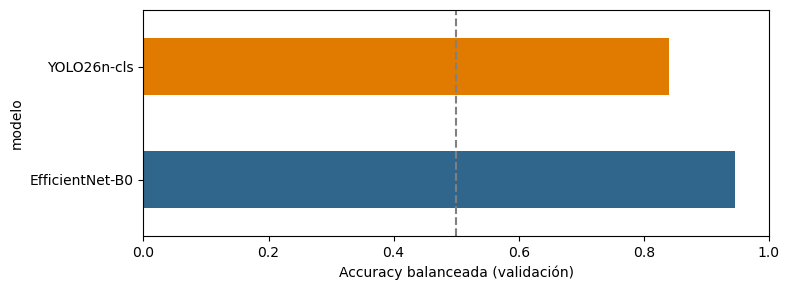

MODELO SELECCIONADO POR VALIDACIÓN: EfficientNet-B0


In [12]:
val_df=pd.DataFrame([{'modelo':k, **v} for k,v in RESULTADOS_VAL.items()]).set_index('modelo')
display(val_df[['accuracy_balanceada','accuracy','precision_defectuosa','recall_defectuosa','f1_defectuosa','fp','fn']].sort_values('accuracy_balanceada',ascending=False))
ax=val_df['accuracy_balanceada'].plot.barh(figsize=(8,3),color=['#30668b','#e07b00'])
ax.axvline(.5,ls='--',color='gray');ax.set_xlim(0,1);ax.set_xlabel('Accuracy balanceada (validación)')
plt.tight_layout();plt.savefig(SALIDA/'comparacion_validacion.png',dpi=160);plt.show()

# Comparación y selección de EfficientNet y YOLO.
candidatos=['EfficientNet-B0','YOLO26n-cls']
SELECCIONADO=max(candidatos,key=lambda k:(RESULTADOS_VAL[k]['accuracy_balanceada'],RESULTADOS_VAL[k]['recall_defectuosa']))
print('MODELO SELECCIONADO POR VALIDACIÓN:',SELECCIONADO)
assert len(RESULTADOS_TEST)==0,'No usar conjunto test antes de elegir modelo'

## 5. Evaluación en prueba

In [14]:
from torch.utils.data import DataLoader
# Modelo EfficientNet: reutiliza checkpoint seleccionado en val.
test_loader=DataLoader(ImageFolder(str(DATOS/'test'),transform=prep),batch_size=32,shuffle=False,num_workers=0)
r_eff,p_eff,s_eff=predecir_eff_loader(modelo,test_loader)
guardar_metricas('EfficientNet-B0','test',r_eff,p_eff,s_eff)

r_yolo=[c for _,c in TEST];p_yolo,s_yolo=predecir_yolo([r for r,_ in TEST])
guardar_metricas('YOLO26n-cls','test',r_yolo,p_yolo,s_yolo)

test_df=pd.DataFrame([{'modelo':k,**v} for k,v in RESULTADOS_TEST.items()]).set_index('modelo')
display(test_df[['accuracy','accuracy_balanceada','precision_defectuosa','recall_defectuosa','f1_defectuosa','auroc','fp','fn']].sort_values('accuracy_balanceada',ascending=False))
print('\nSelección permanece:',SELECCIONADO)
print('\nClassification report del seleccionado (prueba):')
df_sel=PREDICCIONES[(SELECCIONADO,'test')]
print(classification_report(df_sel['real'],df_sel['predicha'],labels=CLASES,zero_division=0))

EfficientNet-B0 / test: accuracy balanceada = 96.43%, F1 defectuosa = 96.30%
YOLO26n-cls / test: accuracy balanceada = 91.70%, F1 defectuosa = 93.27%


,accuracy,accuracy_balanceada,precision_defectuosa,recall_defectuosa,f1_defectuosa,auroc,fp,fn
modelo,,,,,,,,
EfficientNet-B0,0.956989,0.964286,1.000000,0.928571,0.962963,0.997225,0,8
YOLO26n-cls,0.919355,0.916988,0.936937,0.928571,0.932735,0.972370,7,8



Selección permanece: EfficientNet-B0

Classification report del seleccionado (prueba):
              precision    recall  f1-score   support

    correcta       0.90      1.00      0.95        74
  defectuosa       1.00      0.93      0.96       112

    accuracy                           0.96       186
   macro avg       0.95      0.96      0.96       186
weighted avg       0.96      0.96      0.96       186



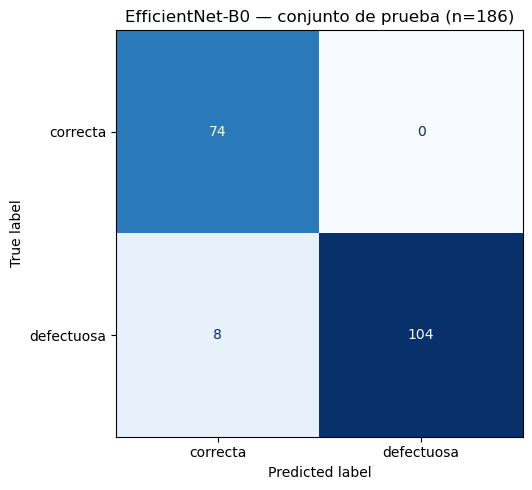

In [15]:
# Matriz de confusión del seleccionado
cm=confusion_matrix(df_sel['real'],df_sel['predicha'],labels=CLASES)
fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay(cm,display_labels=CLASES).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title(f'{SELECCIONADO} — conjunto de prueba (n=186)')
fig.tight_layout();fig.savefig(SALIDA/'matriz_confusion_seleccionado.png',dpi=160);plt.show()

## 6. Análisis de errores

Errores totales: 8 | falsos negativos: 8 | falsos positivos: 0


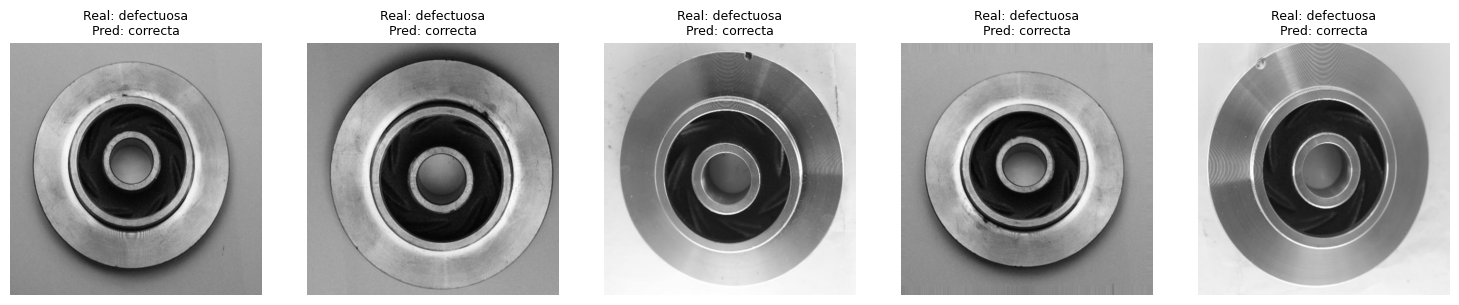

In [17]:
errores=df_sel[df_sel.real!=df_sel.predicha].copy()
fn=errores[(errores.real=='defectuosa')&(errores.predicha=='correcta')]
fp=errores[(errores.real=='correcta')&(errores.predicha=='defectuosa')]
print('Errores totales:',len(errores),'| falsos negativos:',len(fn),'| falsos positivos:',len(fp))
# Priorizar ejemplos de FN por su mayor costo potencial.
ejemplos=pd.concat([fn.head(5),fp.head(5)]).head(10)
if len(ejemplos):
    ncols=min(5,len(ejemplos));nrows=int(np.ceil(len(ejemplos)/ncols))
    fig,axes=plt.subplots(nrows,ncols,figsize=(3*ncols,3*nrows),squeeze=False)
    for ax in axes.ravel():ax.axis('off')
    for ax,(_,fila) in zip(axes.ravel(),ejemplos.iterrows()):
        ax.imshow(Image.open(fila.ruta).convert('RGB'))
        ax.set_title(f'Real: {fila.real}\nPred: {fila.predicha}',fontsize=9)
    fig.tight_layout();fig.savefig(SALIDA/'ejemplos_errores.png',dpi=160);plt.show()
else:print('No hubo errores en las 186 fotos de prueba; comprobar generalización externa antes de concluir perfección.')

## 7. Guardar resultados y modelo seleccionado

In [19]:
# Guardar resultados de ambos, sin editar la selección según el test.
(SALIDA/'metricas_validacion.json').write_text(json.dumps(RESULTADOS_VAL,indent=2,ensure_ascii=False),encoding='utf8')
(SALIDA/'metricas_prueba.json').write_text(json.dumps(RESULTADOS_TEST,indent=2,ensure_ascii=False),encoding='utf8')
val_df.to_csv(SALIDA/'metricas_validacion.csv')
test_df.to_csv(SALIDA/'metricas_prueba.csv')
for (nombre,conjunto),df in PREDICCIONES.items():
    df.to_csv(SALIDA/f'predicciones_{nombre.lower().replace("-","_").replace(" ","_")}_{conjunto}.csv',index=False)
if SELECCIONADO=='YOLO26n-cls':
    peso_destino=SALIDA/'modelo_elegido_yolo26n_cls.pt'
    shutil.copy2(path_best,peso_destino)
else:
    peso_destino=checkpoint_eff  # modelo EfficientNet guardado al finalizar su mejor época

seleccion={'modelo_seleccionado':SELECCIONADO,'criterio':'máxima accuracy balanceada en VALIDACION; desempate recall defectuosa',
           'epochs':2,'tamanos':{'train':928,'val':186,'test':186},'clases':CLASES,
           'metrica_validacion':RESULTADOS_VAL[SELECCIONADO], 'metrica_prueba':RESULTADOS_TEST[SELECCIONADO],
           'ruta_checkpoint':str(peso_destino),'integracion_n8n':'PENDIENTE, no actualizar API antes de desplegar este modelo',
           'advertencia':'Los scores no son probabilidades calibradas; imágenes de Kaggle sin relación real con líneas A/B/C.'}
(SALIDA/'seleccion_modelo.json').write_text(json.dumps(seleccion,ensure_ascii=False,indent=2),encoding='utf8')
print('Modelo elegido:',SELECCIONADO)
print('Checkpoint:',peso_destino)
print('Archivos de métricas, predicciones, gráficos y selección en:',SALIDA.resolve())

Modelo elegido: EfficientNet-B0
Checkpoint: resultados_modelos_imagenes\efficientnet_b0_best.pth
Archivos de métricas, predicciones, gráficos y selección en: C:\Users\renat\123 examen\resultados_modelos_imagenes
